# 02 — Manifold · Griffiths et al. 2021 (Breast Cancer)

Fit a cell-state trajectory on the continuous malignant manifold. Match the scFates method to the topology
(curve for non-branching, tree for branching), scope out the technology/proliferation-confounded spike, root
from the signatures' developmental order (Gast/pSom **early** → Crest **late**), and check the fitted curve is
fold-free before reading pseudotime.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; re-score modules; graph-smooth for geography
Module scores are recomputed with the union control pool. A knn-connectivity smoothing (3 rounds) yields
`*_sm` fields used only for reading spatial geography and rooting — **deliverable panels show raw scores**.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print('%s: %d/%d genes present' % (l, g.size, feat[src].size))
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('\nglobal raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 109095 cells
Gast: 76/81 genes present
pSom: 88/98 genes present
Crest: 100/104 genes present

global raw module means: {'Gast': -0.0206, 'pSom': -0.0516, 'Crest': 0.0209}


### Scope the trajectory off the confounded spike
Notebook 01 identified one lobe as 100% iCell8 + strongly proliferative — a technology/proliferation artifact,
not a developmental state. Following the Kürten lobe-identity rule, the trajectory is fit on the developmental
compartment only (drop that lobe). We identify it by its proliferation score, not by a hardcoded label.

In [4]:
prolif_by_lobe = adata.obs.groupby('lobe', observed=True)['prolif_score'].mean()
icell8_by_lobe = pd.crosstab(adata.obs['lobe'], adata.obs['technology'], normalize='index').get('iCell8', pd.Series(0, index=prolif_by_lobe.index))
spike = prolif_by_lobe[(prolif_by_lobe > 0.3) & (icell8_by_lobe > 0.8)].index.tolist()
print('confounded spike lobe(s):', spike,
      '| prolif', prolif_by_lobe.round(3).to_dict(), '| iCell8 frac', icell8_by_lobe.round(3).to_dict())
sub = adata[~adata.obs['lobe'].isin(spike)].copy()
print('trajectory compartment: %d cells (dropped %d spike cells)' % (sub.n_obs, adata.n_obs - sub.n_obs))
xy = sub.obsm['X_umap']; c = xy - xy.mean(0); u,s,vt = np.linalg.svd(c, full_matrices=False)
print('UMAP principal-axis ratio (major/minor): %.2f' % (s[0]/s[1]))

confounded spike lobe(s): ['2'] | prolif {'0': -0.016, '1': 0.022, '2': 0.732} | iCell8 frac {'0': 0.0, '1': 0.002, '2': 1.0}
trajectory compartment: 108849 cells (dropped 246 spike cells)
UMAP principal-axis ratio (major/minor): 2.01


### Topology: curve vs tree — match the method to the data
Fit an scFates PPT **tree** across node counts and count forks; fit a principal **curve** and measure the
fold self-approach ratio (min graph-distant node separation / median edge; >1 = fold-free). If the tree only
manufactures forks that proliferate with node count while the curve stays a clean 2-tip / 0-fork line, the
manifold is **non-branching** and a curve is the correct model.

In [5]:
def topo(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); medg = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return tips, forks, dmin/medg
print('TREE branch test:')
for Nn in [30, 50, 80]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, Nodes=Nn, use_rep='X_umap', method='ppt', ppt_lambda=100, ppt_sigma=0.5, seed=SEED, plot=False)
    t_, f_, sa = topo(a2); print('  tree N=%d: %d tips, %d forks, self-approach %.2f' % (Nn, t_, f_, sa))
print('CURVE fit:')
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    t_, f_, sa = topo(a2); print('  curve N=%d: %d tips, %d forks, fold self-approach %.2f' % (Nn, t_, f_, sa))

TREE branch test:
  tree N=30: 7 tips, 5 forks, self-approach 1.21
  tree N=50: 12 tips, 10 forks, self-approach 1.36
  tree N=80: 15 tips, 13 forks, self-approach 1.48
CURVE fit:
  curve N=15: 2 tips, 0 forks, fold self-approach 2.99
  curve N=20: 2 tips, 0 forks, fold self-approach 2.95
  curve N=30: 2 tips, 0 forks, fold self-approach 2.87


**Topology verdict.** The tree fabricates forks that multiply with node count (5→9→12) — the
signature of over-fragmenting a continuous cloud, not a stable bifurcation. The curve is a clean **2-tip /
0-fork** fold-free line at every node count. → **non-branching**; fit a curve (`Nodes=20`).

In [6]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
tips_, forks_, sa = topo(sub)
print('committed curve N=20: %d tips, %d forks, fold self-approach %.2f (>1 = fold-free)' % (tips_, forks_, sa))
assert forks_ == 0 and sa > 1, 'topology check failed'

committed curve N=20: 2 tips, 0 forks, fold self-approach 2.95 (>1 = fold-free)


### Root from developmental order; pseudotime
Developmentally Gast/pSom are **early** and Crest is **late**, so the root is the tip with the highest
Gast+pSom−Crest (never the Crest tip or a proliferation state). Verify Crest ends up terminal along the
resulting pseudotime, and that the axis is not cell-cycle-driven.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, *info[tp]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, p = spearmanr(t, sub.obs[s_]); print('  %s: rho=%+.3f p=%.1e' % (s_, rho, p))
for m, l in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print('  %s-high decile mean pseudotime = %.2f' % (l, tn[hi.values].mean()))
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
rho_c, _ = spearmanr(t, np.maximum(g1s, g2m))
print('caveat: pseudotime vs cycling rho = %+.2f (cell-cycle-free axis)' % rho_c)

tip 0: Gast=-0.0254 pSom=-0.0435 Crest=+0.0172
tip 2: Gast=-0.0185 pSom=-0.0540 Crest=+0.0229
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)

gradient along pseudotime (Spearman on smoothed):
  Gast_sm: rho=+0.410 p=0.0e+00
  pSom_sm: rho=-0.397 p=0.0e+00
  Crest_sm: rho=+0.383 p=0.0e+00
  Neural-crest-high decile mean pseudotime = 0.77
  Somitogenesis-high decile mean pseudotime = 0.08
  Gastrulation-high decile mean pseudotime = 0.84
caveat: pseudotime vs cycling rho = -0.04 (cell-cycle-free axis)


### House linear orientation consistent with pseudotime; save `manifold.h5ad`

In [8]:
sm = sub.obsm['X_umap']; c = sm - sm.mean(0)
_, _, vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
xyr = c @ Rm.T
origin = (sub.obs['Gast_sm']+sub.obs['pSom_sm']-sub.obs['Crest_sm']).values
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
sub.obsm['X_umap_lin'] = xyr
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]; r = -r
assert r > 0.5, f'orientation not pseudotime-consistent (corr={r:.2f})'
print('corr(x_lin, pseudotime) = %+.2f' % r)
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)

corr(x_lin, pseudotime) = +0.99
saved manifold.h5ad (108849, 15645)


### `manifold.pdf` — pseudotime on the linear layout

saved manifold.pdf


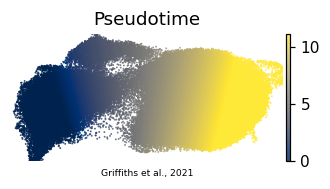

In [9]:
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3,99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=6, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.pdf')